<span style="color: white; font-size: 30px; font-weight: bold;">
NUMERICAL TOOLS FOR QUANTITATIVE FINANCE</span>
<br>
<span style="color: white; font-size: 24px; font-weight: bold;">
Additional topics
</span>

<br>
<span style="color: white; font-size: 24px; font-weight: bold;">
MSc in Mathematics and Finance 2026-2027
</span>
<p></p>
<img src="../Imperial_logo.png" align = "left" width=200>
<br><br>
 
- Copyright (c) Antoine Jacquier, 2026. All rights reserved

- Author: Jack Jacquier <a.jacquier@imperial.ac.uk>

- Platform: Tested on Windows 10 with Python 3.9

In [1]:
import numpy as np

# Matrix algebra

We consider vectors $u,v \in \mathbb{R}^n$ and matrices $A \in \mathcal{M}_{m,n}(\mathbb{R})$
and $B \in \mathcal{M}_{n,p}(\mathbb{R})$.

These can be created directly as `numpy.array` and standard linear algebra computations apply.

### Vectors as `numpy.array`

In [2]:
uu = np.array([1,2,3])

print("Vector u:", uu)
print("Length of the vector u:", len(uu))
print("Shape of the vector u:", uu.shape)

Vector u: [1 2 3]
Length of the vector u: 3
Shape of the vector u: (3,)


In [3]:
uu = np.array([1, 2, 3])
vv = np.array([-1, -2, -3])

print(2.*uu)
print(uu.T)
print(uu*vv)

[2. 4. 6.]
[1 2 3]
[-1 -4 -9]


Is it really what you expect from linear algebra?

## Vectors as `numpy.matrix`

In [4]:
uu = np.matrix([1,2,3])

print("Vector u:", uu)
print("Length of the vector u:", len(uu))
print("Shape of the vector u:", uu.shape)

Vector u: [[1 2 3]]
Length of the vector u: 1
Shape of the vector u: (1, 3)


In [5]:
uu = np.matrix([1, 2, 3])
vv = np.matrix([-1, -2, -3])

print(2.*uu)
print(uu.T)

[[2. 4. 6.]]
[[1]
 [2]
 [3]]


Here, vectors were defined as matrices in one dimension.

We can of course define (classical) matrices in two dimensions:

In [6]:
A = np.matrix([[1,2,3],[4,5,6],[7,8,9], [10, 11, 12]])

print("Matrix A: \n", A)
print("Shape of A:",A.shape)
print("Number of rows in A:",A.shape[0])
print("Number of columns in A:",A.shape[1])

Matrix A: 
 [[ 1  2  3]
 [ 4  5  6]
 [ 7  8  9]
 [10 11 12]]
Shape of A: (4, 3)
Number of rows in A: 4
Number of columns in A: 3


and perform matrix operations:

In [2]:
uu = np.matrix([1, 2, 3])
print("Shape of A:",A.shape)
print("Shape of u:",uu.shape)

print("Transpose of A:", A.T)
print("***********")
print("Product A*u.T", A*uu)

NameError: name 'A' is not defined

From now on, we consider randomly generated vectors and matrices.

**WARNING:** operations have different meanings between `numpy.array` and `numpy.matrix`.

In [17]:
A = np.random.random((2, 1))
B = np.random.random((1, 2))
print("A:", A, A.shape)
print("***********")
print("B:", B, B.shape)
print("***********")
print("A*B:", A*B, (A*B).shape)

A: [[0.6177335 ]
 [0.25005624]] (2, 1)
***********
B: [[0.08073915 0.97468006]] (1, 2)
***********
A*B: [[0.04987528 0.60209252]
 [0.02018933 0.24372483]] (2, 2)


**WARNING:** The operation * above is not a matrix multiplication but a broadcasting operation.

In [18]:
A = np.random.random((2, 1))
B = np.random.random((2, 1))
print("A:", A, A.shape)
print("***********")
print("B:", B, B.shape)
print("***********")
print("A*B:", A*B, (A*B).shape)

A: [[0.91137377]
 [0.31144482]] (2, 1)
***********
B: [[0.19567671]
 [0.91649344]] (2, 1)
***********
A*B: [[0.17833462]
 [0.28543714]] (2, 1)


## The `numpy.dot` product

In [19]:
uu = np.random.random(2)
vv = np.random.random(2)
print("u:", uu)
print("v:", vv)
print("u*v:", uu*vv)
print("dot(u,v)", np.dot(uu, vv))

u: [0.48887141 0.99102734]
v: [0.24718051 0.75890357]
u*v: [0.12083948 0.75209418]
dot(u,v) 0.8729336646025728


## The `numpy.multiply` product

In [20]:
A = np.random.random((2, 1))
B = np.random.random((1, 2))
print("A:", A, A.shape)
print("***********")
print("B:", B, B.shape)
print("***********")
print("A*B:", A*B, (A*B).shape)
print("***********")
print("AB:", np.multiply(A,B))

A: [[0.98031736]
 [0.64509792]] (2, 1)
***********
B: [[0.91376099 0.52525699]] (1, 2)
***********
A*B: [[0.89577576 0.51491855]
 [0.58946531 0.33884219]] (2, 2)
***********
AB: [[0.89577576 0.51491855]
 [0.58946531 0.33884219]]


# Application: Linear regression

Given a set of data points $(\boldsymbol{\mathrm{x}}_i,y_i)_{i=1,\ldots,n}$, 
for $y_i\in\mathbb{R}$ and $\boldsymbol{\mathrm{x}}_i\in \mathbb{R}^p$ for each $i=1,\ldots,n$, 
we want to determine the best linear regression model of the form
$$
y_i = \beta_1 x_{i,1} + \ldots + \beta_p x_{i,p} + \varepsilon_i
 = \sum_{j=1}^{p}\beta_{j} x_{i,j} + \varepsilon_i, 
\qquad\text{for }i=1,\ldots, n,
$$
for some $\boldsymbol{\beta}^\top = (\beta_1,\ldots,\beta_p)\in\mathbb{R}^{p}$, where the sequence $\boldsymbol{\varepsilon}^\top = (\varepsilon_1,\ldots,\varepsilon_n)$ forms an iid sequence of centered random noises with variance $\sigma^2>0$.
We can rewrite this in vector form as
$$
y_i = \boldsymbol{\mathrm{x}}_i^\top \boldsymbol{\beta} + \varepsilon_i,
$$
for each $i=1,\ldots,n$, or in matrix form
$$
\boldsymbol{\mathrm{y}} = \boldsymbol{\mathrm{x}}^\top \boldsymbol{\beta} + \boldsymbol{\varepsilon},
$$

The goal of the least square methods is to minimise the noise (or the error), namely to solve the minimisation problem
$$
\min_{\boldsymbol{\beta}}\left\|\boldsymbol{\mathrm{y}} - \boldsymbol{\mathrm{x}}^\top \boldsymbol{\mathrm{\beta}}\right\|_2^2
= \min_{\boldsymbol{\beta}}\sum_{i=1}^{n}\left(y_i - \boldsymbol{\mathrm{x}}_i^\top \boldsymbol{\beta}\right)^2.
$$
Standard linear regression theory yields the optimal coefficient
$$
\boldsymbol{\beta}^* = \left(\boldsymbol{\mathrm{x}}^\top\boldsymbol{\mathrm{x}}\right)^{-1}\boldsymbol{\mathrm{x}}^\top\boldsymbol{\mathrm{y}}.
$$

### Numerical example: testing daily low vs high

We import data from Yahoo Finance via the `yahoo_fin` module. We will come back later on this.

In [7]:
import yfinance as yf
import matplotlib.pylab as plt
import numpy as np

C:\Users\ajacquie\AppData\Local\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [8]:
ticker = 'AMZN'
start_date = '2022-01-01'
end_date = '2022-12-31'

stock = yf.Ticker(ticker)
historical_data = stock.history(start=start_date, end=end_date)
historical_data.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2022-01-03 00:00:00-05:00,167.550003,170.703506,166.160507,170.404495,63520000,0.0,0.0
2022-01-04 00:00:00-05:00,170.438004,171.399994,166.349503,167.522003,70726000,0.0,0.0
2022-01-05 00:00:00-05:00,166.882996,167.126495,164.356995,164.356995,64302000,0.0,0.0
2022-01-06 00:00:00-05:00,163.450500,164.800003,161.936996,163.253998,51958000,0.0,0.0
2022-01-07 00:00:00-05:00,163.839005,165.243500,162.031006,162.554001,46606000,0.0,0.0


In [9]:
xlabel = "Low"
ylabel = "High"

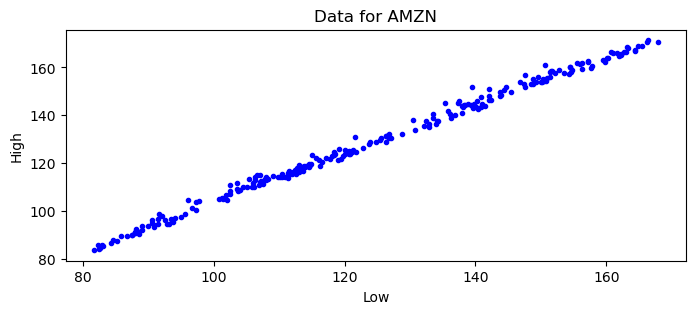

In [10]:
xx = np.array(historical_data[xlabel])
yy = np.array(historical_data[ylabel])
plt.figure(figsize=(8,3))
plt.plot(xx, yy, 'b.')
plt.title("Data for %s" %ticker)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
plt.show()

[[1.01221348]
 [2.99224408]]


C:\Users\ajacquie\AppData\Local\Temp\ipykernel_29932\1821122764.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  plt.title(r'OLS for %s, $\beta$ = (%.2f,%.2f)' %(ticker, beta[0], beta[1]))


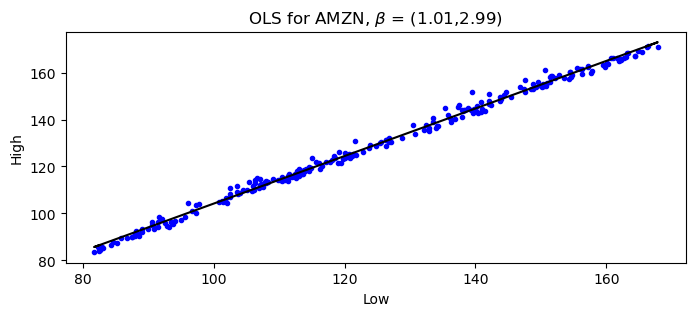

In [11]:
A = np.vstack([xx, np.ones(len(xx))]).T
yy2 = yy[:, np.newaxis]

# Direct least square regression
beta = np.dot((np.dot(np.linalg.inv(np.dot(A.T,A)),A.T)),yy2)

plt.figure(figsize = (8,3))
plt.plot(xx, yy2, 'b.')
plt.plot(xx, beta[0]*xx + beta[1], 'k')
plt.xlabel(xlabel)
plt.ylabel(ylabel)
plt.title(r'OLS for %s, $\beta$ = (%.2f,%.2f)' %(ticker, beta[0], beta[1]))
plt.show()

# Other numerical topics not covered

- linear and non-linear interpolation: https://docs.scipy.org/doc/scipy/tutorial/interpolate.html
- matrix inversion: https://numpy.org/doc/stable/reference/generated/numpy.linalg.inv.html
- spectral decomposition: https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.eig.html